# ME421 — Open-ended vibration modelling laboratory
## Fully worked illustrative solution (Weeks 1–4)
This is one possible solution to the companion laboratory notebook. All dimensions, tension, masses, dashpot settings, absorber constraints and recordings used in the numerical example are **synthetic**, not specifications or measurements of the TM1016V. The apparatus datasheet confirms the displacement sensor, exciter encoder, accelerometer, variable-area dashpot and undamped vibration absorber, but does not establish the numerical values or all mounting options used here. Check the supplied user guide and physical apparatus before implementation. In particular, axial tension is an assumption of the laboratory problem, not a stated feature of the datasheet.

Run the notebook from top to bottom. It generates example CSV files and then imports them as if they were experimental recordings. Replace these files with appropriately formatted measured data for a real investigation. The example uses SI units throughout; plots show millimetres and Hz where convenient.

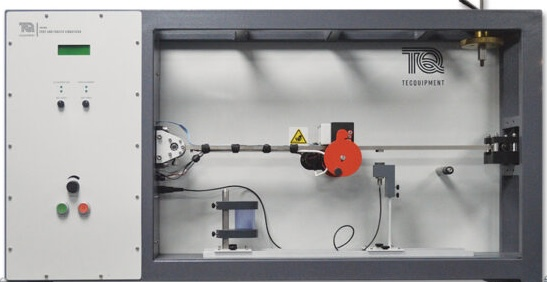

## Resources

- [TecQuipment vibration analyser — video](https://youtu.be/r_ouYEYhR5U)
- [Vibration analysis — Python resources](https://github.com/mugalan/vibration-analysis)
- TecQuipment TM1016V Free and Forced Vibrations datasheet and the user guide available in the laboratory.

The apparatus provides non-contact displacement measurements, acceleration measurements at the exciter, rotational speed and exciter angular position. The VDAS system can also derive velocity and acceleration from displacement measurements. Available components include an adjustable viscous dashpot, additional masses and an undamped vibration absorber. Establish the permissible configurations and adjustment ranges of the actual apparatus before designing experiments.

# Part I — Modelling, identification and validation (end of Week 2)
## Week 1 — Activity 1: mathematical formulation
The beam is modelled as
$$\rho A y_{tt}+EI y_{xxxx}-T y_{xx}=f(x,t).$$
Assume small transverse displacements, uniform cross-section, constant positive axial tension, ideal pins and linear elasticity. About the static equilibrium, gravity is absent from the incremental equations. The boundary conditions are
$$y(0,t)=y(L,t)=0,\qquad y_{xx}(0,t)=y_{xx}(L,t)=0.$$
Let the exciter have total translating mass $m_e$ at $x_f$, and let its rotating eccentric mass and eccentricity have product $u=m_r e$. At constant rotational speed $\omega$, the transverse applied force is $u\omega^2\cos(\omega t)$, with the zero of the encoder angle chosen accordingly. The exciter reaction includes its translating inertia. Any other point masses $m_i$ at $x_i$ contribute similarly. A grounded dashpot at $x_d$ exerts $-c_d y_t(x_d,t)$.

The resulting distributional equation is
$$\rho A y_{tt}+EI y_{xxxx}-T y_{xx}+\sum_i m_i\delta(x-x_i)y_{tt}(x_i,t)+c_d\delta(x-x_d)y_t(x_d,t)=u\omega^2\cos(\omega t)\delta(x-x_f).$$
The sum includes the exciter. This equation explicitly models the dashpot but leaves inherent damping to the reduced model, since classical damping is a modal assumption rather than a unique local PDE law. Attachment mass or stiffness changes due to the dashpot are assumed negligible; this must be checked experimentally.

### Galerkin approximation
Use $y(x,t)=\sum_{j=1}^n\phi_j(x)q_j(t)$, where $\phi_j(x)=\sin(j\pi x/L)$ are admissible functions, not necessarily the loaded-beam eigenmodes. Multiplying by $\phi_i$ and integrating gives
$$M\ddot q+(C_s+c_dbb^T)\dot q+Kq=u\omega^2 a\cos(\omega t),$$
$$M_{ij}=\frac{\rho AL}{2}\delta_{ij}+\sum_k m_k\phi_i(x_k)\phi_j(x_k),\quad K_{ij}=\frac{L}{2}\left[EI(j\pi/L)^4+T(j\pi/L)^2\right]\delta_{ij},$$
$$a_i=\phi_i(x_f),\quad b_i=\phi_i(x_d),\quad h_i=\phi_i(x_m),\qquad y(x_m,t)=h^Tq(t).$$
Solve $KV=MV\Lambda$, with $V^TMV=I$. In the coordinates $q=Vz$, classical inherent damping means
$$D_s=V^TC_sV=\operatorname{diag}(2\zeta_j\omega_j),\qquad C_s=MV D_sV^TM.$$
The dashpot contribution in these coordinates is $c_d(V^Tb)(V^Tb)^T$, generally not diagonal. We do not assume Rayleigh damping or attempt to identify unobservable modal damping coefficients.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from pathlib import Path
from IPython.display import display
rng = np.random.default_rng(421)
DATA = Path('me421_dummy_data'); DATA.mkdir(exist_ok=True)
# Illustrative values only; replace with measured geometry and masses.
L, rho, E, width, thickness, T = .80, 7850., 200e9, .025, .004, 100.
A, I = width*thickness, width*thickness**3/12
xf, xm, xd = L/2, L/2, L*.40
me, u = 1.2, 2.0e-5  # kg, kg m
attached = [(me, xf)]
def basis(x,n): return np.sin(np.arange(1,n+1)*np.pi*x/L)
def beam(n):
    M = np.eye(n)*rho*A*L/2
    for mass,x in attached:
        v=basis(x,n); M += mass*np.outer(v,v)
    k=np.arange(1,n+1)*np.pi/L
    K=np.diag(L/2*(E*I*k**4+T*k**2))
    w2,V=eigh(K,M)
    return M,K,np.sqrt(w2),V
M,K,w,V=beam(9)
print('Beam mass (kg):',rho*A*L)
display(pd.DataFrame({'mode':np.arange(1,5),'frequency_Hz':w[:4]/(2*np.pi),
                      'excitation_coupling':(V.T@basis(xf,9))[:4]}))
display(pd.DataFrame([(n,beam(n)[2][0]/(2*np.pi)) for n in [1,3,5,9,15]],columns=['basis_size','first_frequency_Hz']))

Beam mass (kg): 0.6280000000000001


,mode,frequency_Hz,excitation_coupling
0,1,7.223595,8.150286e-01
1,2,58.933834,-1.879049e-15
2,3,96.120873,-2.823979e-01
3,4,230.613559,-3.804003e-16


,basis_size,first_frequency_Hz
0,1,7.263681
1,3,7.229637
2,5,7.225184
3,9,7.223595
4,15,7.223250


### Model reduction and choice of coordinates
The centered exciter and sensor suppress the antisymmetric modes of the ideal symmetric mass-loaded beam in the absence of the off-centre dashpot. The dashpot can couple modes; near the first resonance we test whether the first loaded-beam mode alone suffices. Normalize its shape to unity at the exciter, $\psi(x)=\phi(x)^TV_1/[\phi(x_f)^TV_1]$, so that $q_1$ represents displacement at the exciter. Define $v=V_1/[\phi(x_f)^TV_1]$, $M_1=v^TMv$, $K_1=v^TKv$, $b_1=\psi(x_d)$ and $h_1=\psi(x_m)$.
$$M_1\ddot q_1+(C_{s1}+c_db_1^2)\dot q_1+K_1q_1=u\omega^2\cos\omega t.$$
In this normalization $C_{s1}=2M_1\omega_1\zeta_1$. Only this inherent coefficient is identified; the full $C_s$ cannot be recovered from first-mode data alone.

M1=1.5054 kg, K1=3101.14 N/m, f1=7.224 Hz, b1=0.944


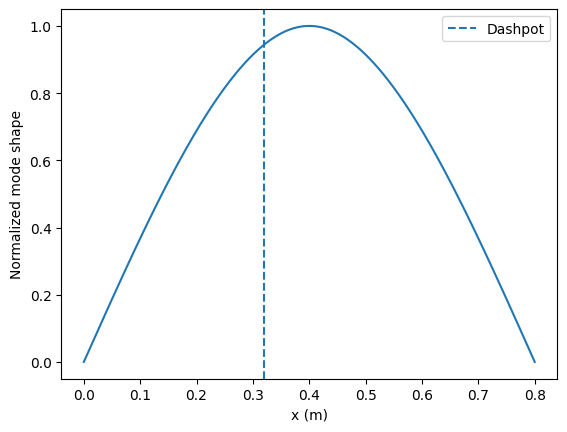

In [2]:
v=V[:,0]/(basis(xf,9)@V[:,0]); M1=v@M@v; K1=v@K@v
w1=np.sqrt(K1/M1); f1=w1/(2*np.pi); b1=basis(xd,9)@v; h1=basis(xm,9)@v
print(f'M1={M1:.4f} kg, K1={K1:.2f} N/m, f1={f1:.3f} Hz, b1={b1:.3f}')
x=np.linspace(0,L,301)
plt.plot(x,[basis(xx,9)@v for xx in x]); plt.axvline(xd,ls='--',label='Dashpot'); plt.xlabel('x (m)'); plt.ylabel('Normalized mode shape'); plt.legend(); plt.show()

## Activity 2 — experimental plan and preliminary simulations
Use repeated free-decay experiments with the dashpot removed and at several settings. Keep masses, tension and positions unchanged. Record displacement versus time after release; use two initial amplitudes and repeat at each setting to assess repeatability and amplitude dependence. A separate forced-response sweep will validate the fitted model rather than being used for calibration. Wait for transients to decay before collecting each steady-state record; use sufficiently fine frequency spacing near peaks. Verify safe amplitudes, motor speed, attachment security, sensor travel and dashpot settings with staff before any run. The sensor and exciter are assumed co-located here for simplicity.

For an underdamped first mode, the free response is
$$y(t)=e^{-\sigma t}[B\cos(\omega_dt)+D\sin(\omega_dt)]+y_0,\quad \omega_n=\sqrt{\omega_d^2+\sigma^2},\quad\zeta=\sigma/\omega_n.$$
For harmonic forcing, the complex steady-state displacement is
$$\hat y=\frac{h_1u\omega^2}{K_1-M_1\omega^2+i\omega(C_{s1}+c_db_1^2)}.$$
The rotating unbalance force is not constant in amplitude; it scales as $\omega^2$. Phase lag is $-\arg\hat y$ for the chosen convention. The following preliminary simulations use provisional damping values, not identified parameters.

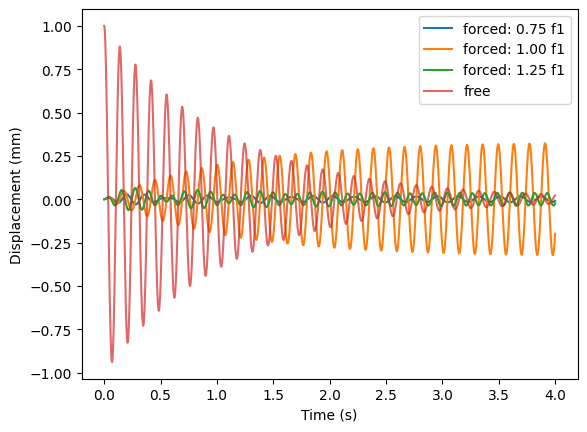

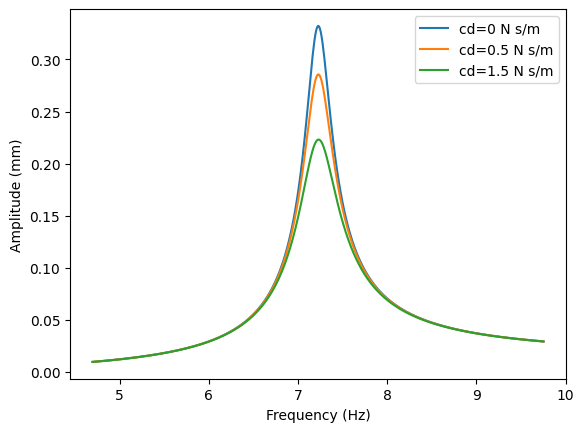

In [3]:
def H1(f,Cs,cd=0):
    om=2*np.pi*np.asarray(f)
    return h1*u*om**2/(K1-M1*om**2+1j*om*(Cs+cd*b1*b1))
Cguess=2*M1*w1*.02
t=np.linspace(0,4,1601)
for r in [.75,1.,1.25]:
    om=r*w1
    sol=solve_ivp(lambda t,z:[z[1],(u*om**2*np.cos(om*t)-Cguess*z[1]-K1*z[0])/M1],
                  [t[0],t[-1]],[0,0],t_eval=t,rtol=1e-7,atol=1e-9)
    plt.plot(t,1000*h1*sol.y[0],label=f'forced: {r:.2f} f1')
sol=solve_ivp(lambda t,z:[z[1],(-Cguess*z[1]-K1*z[0])/M1],[0,t[-1]],[.001,0],t_eval=t)
plt.plot(t,1000*h1*sol.y[0],label='free',alpha=.7); plt.xlabel('Time (s)'); plt.ylabel('Displacement (mm)'); plt.legend(); plt.show()
fgrid=np.linspace(.65*f1,1.35*f1,501)
for cd0 in [0,.5,1.5]: plt.plot(fgrid,1000*abs(H1(fgrid,Cguess,cd0)),label=f'cd={cd0:g} N s/m')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(); plt.show()

## Week 2 — Activity 3: dummy experimental recordings
The next cell acts as a virtual instrument. It uses a nine-function beam model, small measurement noise and run-to-run variation. Higher-mode damping is assumed only inside the synthetic generator; it is not estimated from the data. The unknown ground-truth coefficients must not be used in the estimator. CSV schemas are illustrative, not claimed VDAS export formats.

Free-decay columns: `setting` (-1 means dashpot removed; 0–1 are hypothetical installed settings), `run`, `time_s`, `displacement_m`. Forced-response columns additionally contain frequency, encoder angle and acceleration. The data are generated independently of the first-mode fitting procedure.

In [4]:
# Synthetic instrument only. No ground-truth damping values are passed to the estimator.
from scipy.linalg import expm
from scipy.sparse.linalg import expm_multiply
N=9; aa=V.T@basis(xf,N); bb=V.T@basis(xd,N); hh=V.T@basis(xm,N)
truth_zeta=np.r_[.013,np.full(N-1,.018)]
Ds=np.diag(2*truth_zeta*w)
def true_cd(s): return 0. if s<0 else .18+1.8*s**1.4
settings=[-1.,0.,.25,.5,.75,1.]
records=[]; tfree=np.arange(0,5,.005)
for s in settings:
    for run,amp in enumerate([.0007,.0012,.0007,.0012]):
        cd=true_cd(s)*(1+rng.normal(0,.012)); D=Ds+cd*np.outer(bb,bb)
        # Initially displaced in first mode. Tiny higher-mode contamination.
        z0=np.zeros(N); z0[0]=amp/hh[0]; z0[2]=.000003/(hh[2] or 1)
        state=np.block([[np.zeros((N,N)),np.eye(N)],[-np.diag(w*w),-D]])
        # Uniform-step exact propagation avoids expensive time integration.
        P=expm(state*(tfree[1]-tfree[0])); z=np.r_[z0,np.zeros(N)]; y=[]
        for ti in tfree:
            y.append(hh@z[:N]); z=P@z
        y=np.asarray(y)+rng.normal(0,1.8e-6,len(tfree))+rng.normal(0,2e-6)
        records.append(pd.DataFrame(dict(setting=s,run=run,time_s=tfree,displacement_m=y)))
pd.concat(records,ignore_index=True).to_csv(DATA/'free_decay.csv',index=False)
print('Created',DATA/'free_decay.csv')

Created me421_dummy_data/free_decay.csv


,setting,run,time_s,displacement_m
0,-1.0,0,0.000,0.000705
1,-1.0,0,0.005,0.000678
2,-1.0,0,0.010,0.000633
3,-1.0,0,0.015,0.000541
4,-1.0,0,0.020,0.000436


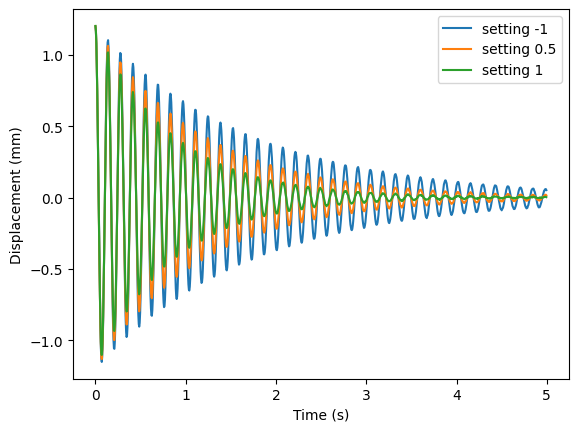

In [5]:
# Import experimental data (replace path with actual exported data after column mapping).
free=pd.read_csv(DATA/'free_decay.csv')
display(free.head())
for s in [-1.,.5,1.]:
    g=free[(free.setting==s)&(free.run==1)]
    plt.plot(g.time_s,1000*g.displacement_m,label=f'setting {s:g}')
plt.xlabel('Time (s)'); plt.ylabel('Displacement (mm)'); plt.legend(); plt.show()

### Estimation of inherent damping and dashpot coefficient
Fit the decaying sinusoid to each run by nonlinear least squares. At a given setting, estimate $\sigma$ and $\omega_d$, then obtain $\zeta$. In the single-mode approximation $C_{\rm total}=2M_1\sigma$, even if the fitted damped frequency varies slightly.
$$\widehat C_{s1}=2M_1\overline\sigma_{\rm removed},\qquad \widehat c_d(s)=\frac{2M_1(\overline\sigma_s-\overline\sigma_{\rm removed})}{b_1^2}.$$
This requires independently known modal mass and nonzero dashpot coupling. With only displacement decays and unknown modal mass, one can identify damping per unit mass, not absolute damping coefficients. A negative estimate beyond uncertainty would indicate a modelling or measurement problem, not a physically negative dashpot. The installed setting zero need not correspond to zero damping. The sample standard deviation across repeated runs is a repeatability indicator, not a full uncertainty budget.

Inherent damping: 1.7765 N s/m; zeta1=0.01300


,sigma,sd,zeta,wn,rmse,cd,cd_se
setting,,,,,,,
-1.00,0.590047,0.000403,0.013000,45.387187,0.000002,0.000000,0.000000
0.00,0.643549,0.000787,0.014179,45.387016,0.000002,0.180603,0.001492
0.25,0.719228,0.001819,0.015847,45.387130,0.000002,0.436069,0.003145
0.50,0.847530,0.003238,0.018673,45.387438,0.000002,0.869172,0.005508
0.75,0.998919,0.005208,0.022009,45.387745,0.000002,1.380211,0.008816
1.00,1.181340,0.005129,0.026028,45.387762,0.000002,1.996001,0.008684


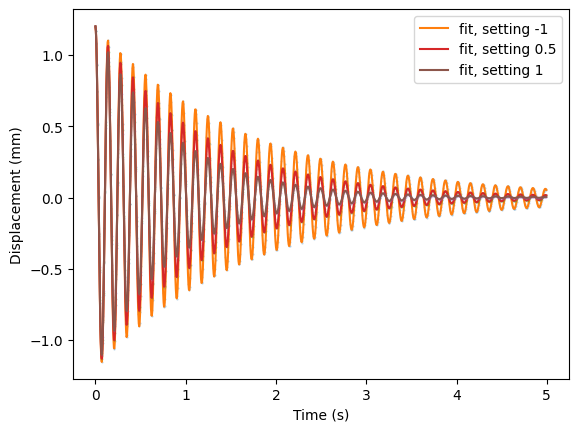

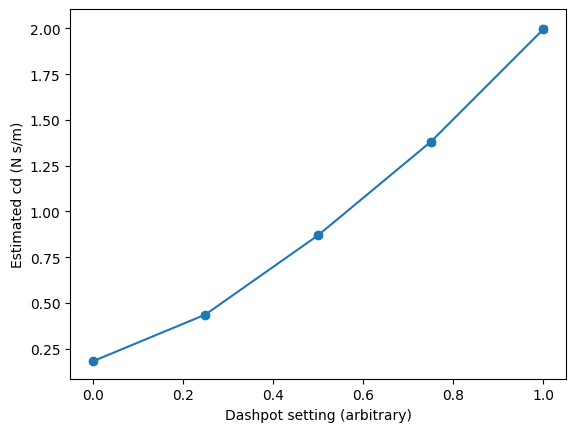

run,small amplitude,large amplitude
setting,,
-1.00,0.013001,0.013000
0.00,0.014188,0.014170
0.25,0.015851,0.015842
0.50,0.018649,0.018697
0.75,0.021956,0.022062
1.00,0.026125,0.025930


In [6]:
def decay(t,B,D,sigma,wd,offset):
    return np.exp(-sigma*t)*(B*np.cos(wd*t)+D*np.sin(wd*t))+offset
def fit_decay(g):
    t=g.time_s.to_numpy(); y=g.displacement_m.to_numpy()
    p0=[y[0],0.,.5,w1,np.mean(y[-100:])]
    res=least_squares(lambda p:(decay(t,*p)-y)/1e-6,p0,
                      bounds=([-np.inf,-np.inf,0,.8*w1,-np.inf],[np.inf,np.inf,10,1.2*w1,np.inf]),
                      x_scale='jac')
    B,D,sigma,wd,offset=res.x; wn=np.hypot(sigma,wd)
    return dict(sigma=sigma,wd=wd,wn=wn,zeta=sigma/wn,rmse=np.sqrt(np.mean((decay(t,*res.x)-y)**2))),res.x
fits=[]
for (s,r),g in free.groupby(['setting','run']):
    est,_=fit_decay(g); fits.append(dict(setting=s,run=r,**est))
fit=pd.DataFrame(fits); summary=fit.groupby('setting').agg(sigma=('sigma','mean'),sd=('sigma','std'),zeta=('zeta','mean'),wn=('wn','mean'),rmse=('rmse','mean'))
Cs=2*M1*summary.loc[-1,'sigma']; summary['cd']=2*M1*(summary.sigma-summary.loc[-1,'sigma'])/b1**2
summary['cd_se']=2*M1/b1**2*np.sqrt((summary.sd**2+summary.loc[-1,'sd']**2)/4); summary.loc[-1,'cd_se']=0
print(f'Inherent damping: {Cs:.4f} N s/m; zeta1={Cs/(2*M1*w1):.5f}')
display(summary.round(6))
for s in [-1.,.5,1.]:
    g=free[(free.setting==s)&(free.run==1)]; _,pfit=fit_decay(g)
    plt.plot(g.time_s,1000*g.displacement_m,'.',ms=1,alpha=.3)
    plt.plot(g.time_s,1000*decay(g.time_s,*pfit),label=f'fit, setting {s:g}')
plt.xlabel('Time (s)'); plt.ylabel('Displacement (mm)'); plt.legend(); plt.show()
cal=summary.loc[summary.index>=0]; plt.errorbar(cal.index,cal.cd,yerr=2*cal.cd_se,fmt='o-',capsize=3)
plt.xlabel('Dashpot setting (arbitrary)'); plt.ylabel('Estimated cd (N s/m)'); plt.show()
def cd_est(s):
    if s==-1: return 0.
    if not 0<=s<=1: raise ValueError('Setting outside calibrated range')
    return float(np.interp(s,cal.index,cal.cd))
# Compare repeatability between initial amplitudes.
display(fit.groupby(['setting',fit.run%2]).zeta.mean().unstack().rename(columns={0:'small amplitude',1:'large amplitude'}))

## Activity 4 — independent forced-response validation
Use a new sweep for the original system and an installed dashpot setting of 0.5. Estimate harmonic coefficients by regression against the encoder angle: $y=B\cos\theta+D\sin\theta+y_0$. The complex amplitude is $B-iD$. Apply the same regression to acceleration and compare with $-\omega^2\hat y$ at the exciter. Because our displacement sensor is co-located in the synthetic experiment, the two measurements are directly comparable.

The synthetic instrument below also supports the absorber experiment in Week 4. Its nine-mode model introduces a small additional modelling discrepancy compared with the identified one-mode model.

,config,setting,frequency_Hz,H,Hacc
0,bare,-1.0,5.417696,0.000017-0.000001j,-0.019152+0.001267j
1,bare,-1.0,5.477893,0.000018-0.000001j,-0.020905+0.001747j
2,bare,-1.0,5.538089,0.000019-0.000001j,-0.023119+0.001288j
3,bare,-1.0,5.598286,0.000020-0.000001j,-0.024201+0.001550j
4,bare,-1.0,5.658483,0.000021-0.000001j,-0.027075+0.001972j


bare complex RMSE (mm): 0.0008 measured/predicted peak (Hz, mm): (np.float64(7.224), np.float64(0.512)) (np.float64(7.225), np.float64(0.511))
Acceleration consistency RMSE (m/s²): 0.0033
dashpot complex RMSE (mm): 0.0007 measured/predicted peak (Hz, mm): (np.float64(7.224), np.float64(0.353)) (np.float64(7.226), np.float64(0.356))
Acceleration consistency RMSE (m/s²): 0.0024


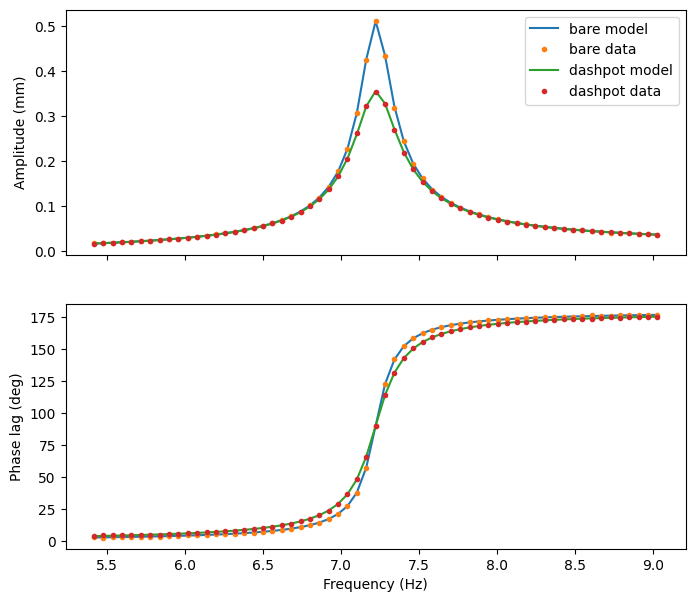

In [7]:
def virtual_H(f,s,absorber=None):
    om=2*np.pi*f; D=Ds+true_cd(s)*np.outer(bb,bb)
    MM=np.eye(N); KK=np.diag(w*w); force=u*om**2*aa
    if absorber is not None:
        ma,fa,xa=absorber; ka=ma*(2*np.pi*fa)**2; g=V.T@basis(xa,N)
        MM=np.diag(np.r_[np.ones(N),ma]); D=np.pad(D,((0,1),(0,1)))
        KK=np.pad(KK,((0,1),(0,1)))+ka*np.outer(np.r_[g,-1],np.r_[g,-1]); force=np.r_[force,0.]
    z=np.linalg.solve(KK-om**2*MM+1j*om*D,force)
    return hh@z[:N],aa@z[:N]
def write_sweep(path,configs,freqs):
    rows=[]
    for name,s,absr in configs:
        for f in freqs:
            H,Hf=virtual_H(f,s,absr); H*=1+rng.normal(0,.006); Hf*=1+rng.normal(0,.006)
            tt=np.arange(0,1.5,.0025); theta=2*np.pi*f*tt+.23; e=np.exp(1j*theta)
            rows.append(pd.DataFrame(dict(config=name,setting=s,frequency_Hz=f,time_s=tt,encoder_rad=theta,
                displacement_m=np.real(H*e)+rng.normal(0,2e-6,len(tt)),
                acceleration_m_s2=np.real(-(2*np.pi*f)**2*Hf*e)+rng.normal(0,.008,len(tt)))))
    pd.concat(rows,ignore_index=True).to_csv(path,index=False)
    return path
write_sweep(DATA/'validation_sweep.csv',[('bare',-1,None),('dashpot',.5,None)],np.linspace(.75*f1,1.25*f1,61))
def extract_sweep(path):
    raw=pd.read_csv(path); rows=[]
    for (name,s,f),g in raw.groupby(['config','setting','frequency_Hz']):
        theta=g.encoder_rad.to_numpy(); X=np.column_stack([np.cos(theta),np.sin(theta),np.ones(len(theta))])
        B,D,_=np.linalg.lstsq(X,g.displacement_m,rcond=None)[0]
        Ba,Da,_=np.linalg.lstsq(X,g.acceleration_m_s2,rcond=None)[0]
        rows.append(dict(config=name,setting=s,frequency_Hz=f,H=B-1j*D,Hacc=Ba-1j*Da))
    return pd.DataFrame(rows)
val=extract_sweep(DATA/'validation_sweep.csv'); display(val.head())
fig,axs=plt.subplots(2,1,figsize=(8,7),sharex=True)
for name,g in val.groupby('config'):
    f=g.frequency_Hz.to_numpy(); obs=g.H.to_numpy(); s=g.setting.iloc[0]; pred=H1(f,Cs,cd_est(s))
    axs[0].plot(f,1000*abs(pred),label=name+' model'); axs[0].plot(f,1000*abs(obs),'.',label=name+' data')
    axs[1].plot(f,-np.angle(pred,deg=True)); axs[1].plot(f,-np.angle(obs,deg=True),'.')
    rmse=np.sqrt(np.mean(abs(pred-obs)**2)); dense=np.linspace(f.min(),f.max(),10001); pp=abs(H1(dense,Cs,cd_est(s)))
    print(name, 'complex RMSE (mm):',round(1000*rmse,4), 'measured/predicted peak (Hz, mm):',
          (round(f[np.argmax(abs(obs))],3),round(1000*max(abs(obs)),3)),(round(dense[np.argmax(pp)],3),round(1000*max(pp),3)))
    acc_error=np.sqrt(np.mean(abs(g.Hacc.to_numpy()+(2*np.pi*f)**2*obs)**2))
    print('Acceleration consistency RMSE (m/s²):',round(acc_error,4))
axs[0].set_ylabel('Amplitude (mm)'); axs[0].legend(); axs[1].set_ylabel('Phase lag (deg)'); axs[1].set_xlabel('Frequency (Hz)'); plt.show()

For the SDOF rotating-unbalance response the peak occurs at $\omega_n/\sqrt{1-2\zeta^2}$ when $\zeta<1/\sqrt2$; this differs from the fixed-force resonance formula. The independently measured sweep may miss the exact peak because of finite frequency spacing. Compare model residuals with measurement noise and check whether increasing the model order would materially improve prediction. The first-mode approximation is justified only over the tested band, not for all frequencies.

### Part I conclusion (end of Week 2)
The free-decay results identify the inherent first-mode damping and an effective calibration of the dashpot. Repeatability and amplitude checks are available above. The independent sweep tests both amplitude and phase. The baseline for Part II is the system with the dashpot at setting 0.5; the bare system is also retained for comparison. Full modal damping, real equipment tension and mounting constraints have not been experimentally established by this synthetic example.

# Part II — vibration absorber design and implementation (end of Week 4)
## Week 3 — Activity 5: extend the model
Let $r(t)$ denote the absolute displacement of the absorber mass $m_a$. Attach an ideal undamped spring $k_a$ at $x_a$, with $g_i=\phi_i(x_a)$. The force on the beam is $k_a(r-g^Tq)$, and the absorber obeys $m_a\ddot r+k_a(r-g^Tq)=0$. The extended matrices are
$$\widetilde M=\begin{bmatrix}M&0\\0&m_a\end{bmatrix},\quad\widetilde C=\begin{bmatrix}C_s+c_dbb^T&0\\0&0\end{bmatrix},\quad\widetilde K=\begin{bmatrix}K+k_agg^T&-k_ag\\-k_ag^T&k_a\end{bmatrix}.$$
The excitation is $[a^T,0]^Tu\omega^2\cos\omega t$. For the first-mode approximation, replace $M,K,C_s,b,g,a$ by $M_1,K_1,C_{s1},b_1,\psi(x_a),1$. In the frequency domain,
$$\hat Q=(\widetilde K-\omega^2\widetilde M+i\omega\widetilde C)^{-1}\begin{bmatrix}u\omega^2\\0\end{bmatrix}.$$
The sensor amplitude is $|h_1\hat Q_1|$, and the absorber relative stroke amplitude is $|\hat Q_2-\psi(x_a)\hat Q_1|$. At $\omega=\sqrt{k_a/m_a}$ the ideal absorber equation requires zero displacement at its attachment; for the single-mode model with nonzero coupling, this implies zero beam response. In a multi-mode beam, other locations need not have zero displacement. The absorber introduces two nearby resonances; reducing vibration at one frequency alone is not sufficient for a variable-speed machine.

Selected ma=0.240 kg, fa=7.238 Hz, ka=496.38 N/m
Robust peak reduction vs fixed dashpot baseline: 97.0%
Worst tested stroke: 1.361 mm
Undamped coupled frequencies (Hz): [5.92876604 8.81881352]


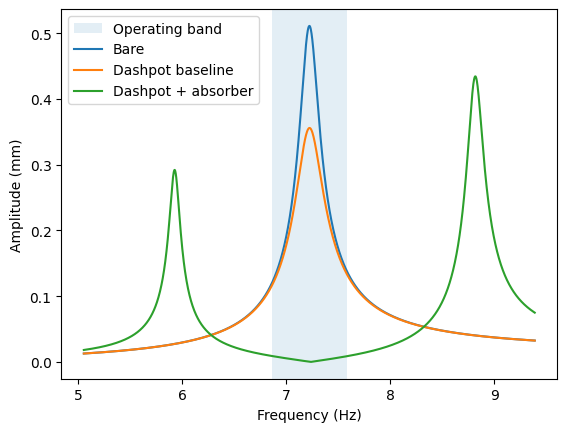

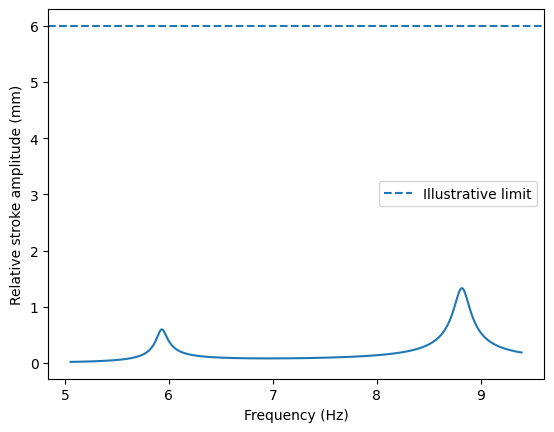

In [8]:
def absorber_H(f,ma,fa,xa,s):
    f=np.asarray(f); om=2*np.pi*f; ka=ma*(2*np.pi*fa)**2; g=basis(xa,9)@v
    MM=np.diag([M1,ma]); CC=np.diag([Cs+cd_est(s)*b1*b1,0.]); KK=np.array([[K1+ka*g*g,-ka*g],[-ka*g,ka]])
    mat=KK-om[...,None,None]**2*MM+1j*om[...,None,None]*CC
    F=np.stack([u*om**2,np.zeros_like(om)],axis=-1)
    Q=np.linalg.solve(mat,F[...,None])[...,0]
    return h1*Q[...,0], Q[...,1]-g*Q[...,0], np.sqrt(eigh(KK,MM,eigvals_only=True))/(2*np.pi)
# Hypothetical design envelope, NOT equipment limits.
# Keep dashpot setting fixed so improvement is attributable to absorber.
s_base=.5; xa=L/2
band=np.linspace(.95*f1,1.05*f1,601); check=np.linspace(.70*f1,1.30*f1,1801)
base_peak=max(abs(H1(band,Cs,cd_est(s_base))))
# Assume three candidate moving masses and a continuous tuning interval.
# Actual adjustable mass/stiffness range must be confirmed.
rows=[]
for ma in [.12,.18,.24]:
    for fa in np.linspace(.94*f1,1.06*f1,121):
        H,stroke,_=absorber_H(band,ma,fa,xa,s_base)
        # Robust objective over ±1% tuning uncertainty, and both band and wider sweep for stroke.
        worst=0.; maxstroke=0.
        for err in [-.01,0,.01]:
            Hr,Sr,_=absorber_H(band,ma,fa*(1+err),xa,s_base)
            _,Sc,_=absorber_H(check,ma,fa*(1+err),xa,s_base)
            worst=max(worst,max(abs(Hr))); maxstroke=max(maxstroke,max(abs(Sc)))
        rows.append(dict(ma=ma,fa=fa,ka=ma*(2*np.pi*fa)**2,worst_m=worst,stroke_m=maxstroke))
designs=pd.DataFrame(rows); stroke_limit=.006 # illustrative 6 mm amplitude constraint
feasible=designs[designs.stroke_m<=stroke_limit]
if feasible.empty: raise RuntimeError('No feasible candidate: revise the illustrative design envelope')
best=feasible.sort_values(['worst_m','ma']).iloc[0]; ma,fa,ka=best[['ma','fa','ka']]
print(f'Selected ma={ma:.3f} kg, fa={fa:.3f} Hz, ka={ka:.2f} N/m')
print(f'Robust peak reduction vs fixed dashpot baseline: {100*(1-best.worst_m/base_peak):.1f}%')
print(f'Worst tested stroke: {1000*best.stroke_m:.3f} mm')
H,S,modes=absorber_H(check,ma,fa,xa,s_base); print('Undamped coupled frequencies (Hz):',modes)
plt.axvspan(band.min(),band.max(),alpha=.12,label='Operating band')
plt.plot(check,1000*abs(H1(check,Cs)),label='Bare')
plt.plot(check,1000*abs(H1(check,Cs,cd_est(s_base))),label='Dashpot baseline')
plt.plot(check,1000*abs(H),label='Dashpot + absorber'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(); plt.show()
plt.plot(check,1000*abs(S)); plt.axhline(1000*stroke_limit,ls='--',label='Illustrative limit'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Relative stroke amplitude (mm)'); plt.legend(); plt.show()

### Design justification and implementation plan
The operating range is chosen as ±5% of the original first natural frequency to represent modest speed variation. The criterion is the maximum sensor displacement amplitude across this band, including three tested tuning errors of −1%, 0 and +1%. This is a sampled robustness check, not a rigorous bound for all errors. The chosen dashpot setting is unchanged from the baseline. Candidate absorber masses, mounting position and stroke limit are hypothetical; on the real apparatus select from measured feasible configurations. The wider sweep reveals the additional resonances and stroke demand; any actual experiment must remain within staff-approved amplitude, speed and stroke limits. A dense numerical sweep is not permission to run through unsafe resonances.

Before Week 4, measure the absorber's effective moving mass and verify its tuning independently if possible. Account for any fixed bracket mass in the beam model. Secure all components, establish a safe start/stop sequence and select frequency increments small enough to resolve peaks. Record the same sensor signal and encoder phase at each speed after transients decay. If the absorber and dashpot cannot be mounted together, repeat design calculations for the physically permitted configuration.

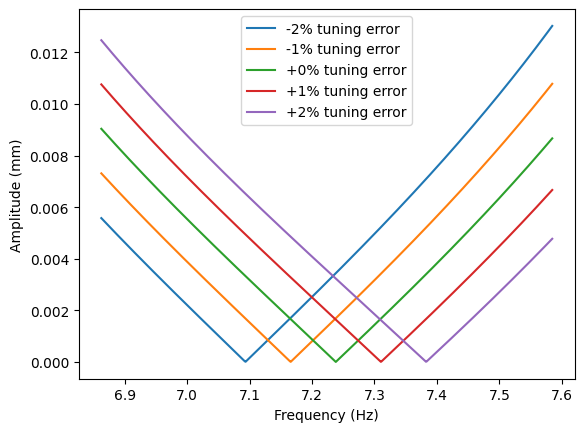

Dashpot -1: predicted in-band peak 0.0090 mm
Dashpot 0: predicted in-band peak 0.0090 mm
Dashpot 0.5: predicted in-band peak 0.0090 mm
Dashpot 1: predicted in-band peak 0.0090 mm


In [9]:
# Sensitivity plots and a comparison with single-frequency tuning.
for err in [-.02,-.01,0,.01,.02]:
    HH,_,_=absorber_H(band,ma,fa*(1+err),xa,s_base)
    plt.plot(band,1000*abs(HH),label=f'{100*err:+.0f}% tuning error')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(); plt.show()
for s in [-1,0,.5,1]:
    HH,_,_=absorber_H(band,ma,fa,xa,s)
    print(f'Dashpot {s:g}: predicted in-band peak {1000*max(abs(HH)):.4f} mm')

## Week 4 — Activity 6: synthetic implementation and independent verification
The virtual instrument now generates fresh recordings for the bare beam, fixed dashpot baseline, and selected absorber combined with the dashpot. A 0.5% tuning offset represents a small implementation error. It is not used to refit the model before comparison. This is a simulated implementation, not evidence that a real device has been installed or tested.

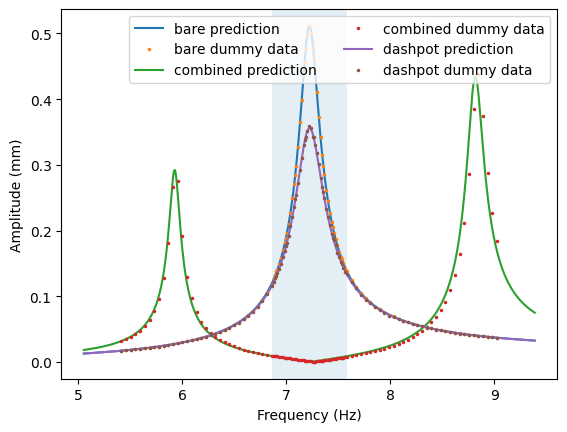

,measured_peak_mm,predicted_peak_mm,complex_rmse_mm
config,,,
bare,0.51143,0.51097,0.00102
combined,0.00973,0.00904,0.02353
dashpot,0.35901,0.35573,0.00099


Illustrative measured reduction relative to dashpot baseline: 97.3%


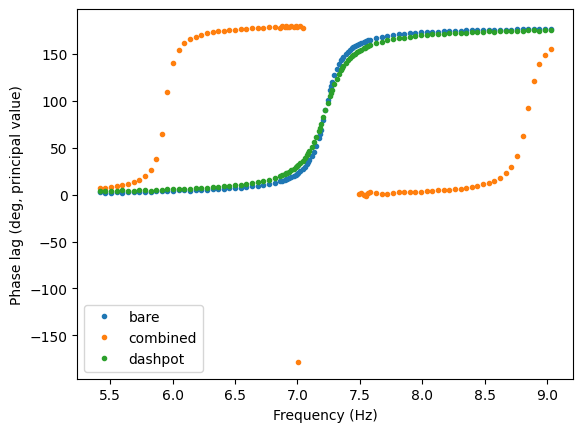

In [10]:
verify_freq=np.unique(np.r_[np.linspace(.75*f1,1.25*f1,81),np.linspace(band.min(),band.max(),41)])
write_sweep(DATA/'absorber_verification.csv',[
    ('bare',-1,None),('dashpot',s_base,None),('combined',s_base,(ma,fa*1.005,xa))],verify_freq)
ver=extract_sweep(DATA/'absorber_verification.csv')
plt.axvspan(band.min(),band.max(),alpha=.12)
for name,g in ver.groupby('config'):
    f=g.frequency_Hz.to_numpy(); obs=g.H.to_numpy()
    pred=absorber_H(check,ma,fa,xa,s_base)[0] if name=='combined' else H1(check,Cs,cd_est(g.setting.iloc[0]))
    plt.plot(check,1000*abs(pred),label=name+' prediction'); plt.plot(f,1000*abs(obs),'.',ms=3,label=name+' dummy data')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(ncol=2); plt.show()
rows=[]
for name,g in ver.groupby('config'):
    f=g.frequency_Hz.to_numpy(); obs=g.H.to_numpy(); mask=(f>=band.min()-1e-9)&(f<=band.max()+1e-9)
    pred=absorber_H(f,ma,fa,xa,s_base)[0] if name=='combined' else H1(f,Cs,cd_est(g.setting.iloc[0]))
    rows.append(dict(config=name,measured_peak_mm=1000*max(abs(obs[mask])),predicted_peak_mm=1000*max(abs(pred[mask])),complex_rmse_mm=1000*np.sqrt(np.mean(abs(pred-obs)**2))))
results=pd.DataFrame(rows).set_index('config'); display(results.round(5))
reduction=100*(1-results.loc['combined','measured_peak_mm']/results.loc['dashpot','measured_peak_mm'])
print(f'Illustrative measured reduction relative to dashpot baseline: {reduction:.1f}%')
# Phase is ill-conditioned at antiresonance; omit points below 5 micrometres.
for name,g in ver.groupby('config'):
    ok=abs(g.H)>5e-6; plt.plot(g.frequency_Hz[ok],-np.angle(g.H[ok],deg=True),'.',label=name)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Phase lag (deg, principal value)'); plt.legend(); plt.show()

### Conclusions and critical evaluation (end of Week 4)
The numerical and synthetic experimental results above demonstrate how to move from a distributed beam model to a calibrated first-mode approximation and then to an absorber design. The comparison against the fixed-dashpot baseline isolates the effect of the absorber. The design targets a limited speed range; the two additional peaks outside or near that range and the relative absorber stroke must be examined before installation. Tuning error, neglected higher modes, non-viscous losses, attachment mass and uncertain tension can all affect real performance. A discrepancy between prediction and measurement is a reason to investigate and revise the model, not to discard the measurement.

For actual submission, replace synthetic data with measured recordings, provide the verified equipment constraints, repeat the uncertainty assessment, report the actual achieved reduction and document any necessary design changes. This example identifies only the first-mode inherent damping, not a complete physical structural damping law. The assumed dashpot calibration and absorber feasibility must be independently established on the actual equipment.

In [11]:
# Export data and useful estimated results for reproducibility.
import shutil
summary.to_csv(DATA/'estimated_damping.csv'); results.to_csv(DATA/'verification_summary.csv')
archive=shutil.make_archive('ME421_dummy_data','zip',DATA)
print('Data archive:',archive)
# In Colab, uncomment to download:
# from google.colab import files
# files.download(archive)

Data archive: /mnt/data/ME421_dummy_data.zip
